In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/README.md
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/A/train_1.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/A/train_10.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/A/train_2.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/A/train_3.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/A/train_4.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/A/train_5.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/A/train_6.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/A/train_7.png
/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+/small_train/A/train_8.png
/kaggle/input/datasets/si

In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        for f in files[:5]:
            print("  " * (level + 1) + f)

input/
  datasets/
    simranmaniyar/
      levir-cd-change-detection/
      s-looking/


In [3]:
DATA_ROOT = "/kaggle/input/levir-cd-change-detection/LEVIR-CD"

In [4]:
import os

DATA_ROOT = "/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection"

for root, dirs, files in os.walk(DATA_ROOT):
    level = root.replace(DATA_ROOT, "").count(os.sep)
    if level <= 4:
        print("  " * level + os.path.basename(root) + "/")
        for f in files[:5]:
            print("  " * (level + 1) + f)

levir-cd-change-detection/
  LEVIR-CD+/
    README.md
    small_train/
      A/
        train_1.png
        train_10.png
        train_2.png
        train_3.png
        train_4.png
      B/
        train_1.png
        train_10.png
        train_2.png
        train_3.png
        train_4.png
      label/
        train_1.png
        train_10.png
        train_2.png
        train_3.png
        train_4.png
    test/
      A/
        train_638.png
        train_639.png
        train_640.png
        train_641.png
        train_642.png
      B/
        train_638.png
        train_639.png
        train_640.png
        train_641.png
        train_642.png
      label/
        train_638.png
        train_639.png
        train_640.png
        train_641.png
        train_642.png
    train/
      A/
        train_1.png
        train_10.png
        train_100.png
        train_101.png
        train_102.png
      B/
        train_1.png
        train_10.png
        train_100.png
        train_101.png
   


train:
  A images: 637
  B images: 637
  Labels:   637
  Missing B:     0
  Missing label: 0

small_train:
  A images: 10
  B images: 10
  Labels:   10
  Missing B:     0
  Missing label: 0

test:
  A images: 348
  B images: 348
  Labels:   348
  Missing B:     0
  Missing label: 0

Filename overlap:
small_train ∩ train: 10
small_train ∩ test:  0

A/train_1.png: size=(1024, 1024), mode=RGB

B/train_1.png: size=(1024, 1024), mode=RGB

label/train_1.png: size=(1024, 1024), mode=L
Mask unique values: [  0 255]


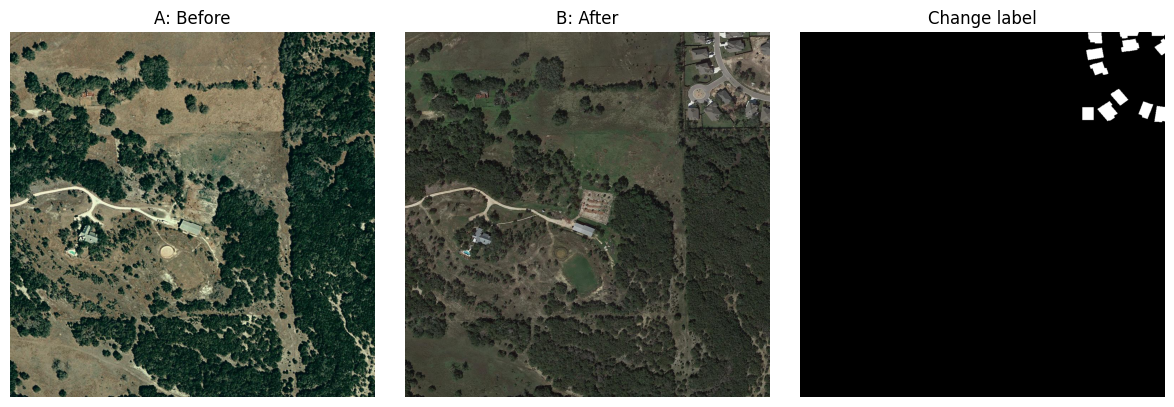

In [5]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

DATA_ROOT = Path(
    "/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+"
)

splits = ["train", "small_train", "test"]

# 1. Count images and check whether A, B, and label filenames match
split_files = {}

for split in splits:
    split_dir = DATA_ROOT / split
    A_files = {p.name for p in (split_dir / "A").glob("*.png")}
    B_files = {p.name for p in (split_dir / "B").glob("*.png")}
    L_files = {p.name for p in (split_dir / "label").glob("*.png")}

    split_files[split] = A_files

    print(f"\n{split}:")
    print(f"  A images: {len(A_files)}")
    print(f"  B images: {len(B_files)}")
    print(f"  Labels:   {len(L_files)}")
    print(f"  Missing B:     {len(A_files - B_files)}")
    print(f"  Missing label: {len(A_files - L_files)}")

# 2. Check overlap between small_train and train
print("\nFilename overlap:")
print("small_train ∩ train:", len(split_files["small_train"] & split_files["train"]))
print("small_train ∩ test: ", len(split_files["small_train"] & split_files["test"]))

# 3. Inspect dimensions and mask values for a sample
sample_name = sorted(split_files["train"])[0]

for folder in ["A", "B", "label"]:
    path = DATA_ROOT / "train" / folder / sample_name
    with Image.open(path) as im:
        print(f"\n{folder}/{sample_name}: size={im.size}, mode={im.mode}")
        if folder == "label":
            mask = np.array(im)
            print("Mask unique values:", np.unique(mask)[:30])

# 4. Display the sample triplet
img_A = np.array(Image.open(DATA_ROOT / "train" / "A" / sample_name).convert("RGB"))
img_B = np.array(Image.open(DATA_ROOT / "train" / "B" / sample_name).convert("RGB"))
mask = np.array(Image.open(DATA_ROOT / "train" / "label" / sample_name))

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(img_A)
plt.title("A: Before")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(img_B)
plt.title("B: After")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mask, cmap="gray")
plt.title("Change label")
plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
import random
from pathlib import Path

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

# -------------------------
# 1. Reproducibility/device
# -------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

DATA_ROOT = Path(
    "/kaggle/input/datasets/simranmaniyar/levir-cd-change-detection/LEVIR-CD+"
)
IMAGE_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 5

# -------------------------
# 2. Dataset
# -------------------------
class ChangeDataset(Dataset):
    def __init__(self, root, split="train", image_size=256):
        self.split_dir = Path(root) / split
        self.image_dir_A = self.split_dir / "A"
        self.image_dir_B = self.split_dir / "B"
        self.label_dir = self.split_dir / "label"

        # Use matching filenames from A, not small_train
        self.names = sorted(
            p.name for p in self.image_dir_A.glob("*.png")
            if (self.image_dir_B / p.name).exists()
            and (self.label_dir / p.name).exists()
        )
        self.image_size = image_size

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        name = self.names[idx]

        img_A = Image.open(self.image_dir_A / name).convert("RGB")
        img_B = Image.open(self.image_dir_B / name).convert("RGB")
        mask = Image.open(self.label_dir / name).convert("L")

        # Images: bilinear resize; masks: nearest-neighbor resize
        img_A = img_A.resize(
            (self.image_size, self.image_size), Image.Resampling.BILINEAR
        )
        img_B = img_B.resize(
            (self.image_size, self.image_size), Image.Resampling.BILINEAR
        )
        mask = mask.resize(
            (self.image_size, self.image_size), Image.Resampling.NEAREST
        )

        img_A = np.asarray(img_A, dtype=np.float32) / 255.0
        img_B = np.asarray(img_B, dtype=np.float32) / 255.0
        mask = np.asarray(mask, dtype=np.uint8)

        # Concatenate before/after RGB images: 6 channels
        image = np.concatenate([img_A, img_B], axis=2)
        image = torch.from_numpy(image).permute(2, 0, 1).float()

        # Label pixels are 0 or 255; convert to 0/1
        mask = torch.from_numpy((mask > 0).astype(np.float32)).unsqueeze(0)

        return image, mask


full_train_ds = ChangeDataset(DATA_ROOT, "train", IMAGE_SIZE)

# Fixed split so reruns use the same train/validation examples
val_count = max(1, int(0.15 * len(full_train_ds)))
train_count = len(full_train_ds) - val_count

train_ds, val_ds = random_split(
    full_train_ds,
    [train_count, val_count],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=(device.type == "cuda")
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=(device.type == "cuda")
)

print(f"Training samples: {len(train_ds)}")
print(f"Validation samples: {len(val_ds)}")

# -------------------------
# 3. Small U-Net
# -------------------------
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, 3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
    )

class SmallUNet(nn.Module):
    def __init__(self, in_channels=6, out_channels=1, base=32):
        super().__init__()
        self.enc1 = conv_block(in_channels, base)
        self.enc2 = conv_block(base, base * 2)
        self.enc3 = conv_block(base * 2, base * 4)
        self.enc4 = conv_block(base * 4, base * 8)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = conv_block(base * 8, base * 16)

        self.up4 = nn.ConvTranspose2d(base * 16, base * 8, 2, stride=2)
        self.dec4 = conv_block(base * 16, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = conv_block(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = conv_block(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = conv_block(base * 2, base)

        self.output = nn.Conv2d(base, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.output(d1)  # logits; sigmoid applied for probabilities


model = SmallUNet().to(device)

# -------------------------
# 4. Loss and metric
# -------------------------
bce_loss = nn.BCEWithLogitsLoss()

def dice_loss(logits, targets, eps=1e-6):
    probs = torch.sigmoid(logits)
    intersection = (probs * targets).sum(dim=(1, 2, 3))
    denominator = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    dice = (2 * intersection + eps) / (denominator + eps)
    return 1 - dice.mean()

def combined_loss(logits, targets):
    return bce_loss(logits, targets) + dice_loss(logits, targets)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    tp = fp = fn = 0

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        logits = model(images)
        loss = combined_loss(logits, masks)
        total_loss += loss.item() * images.size(0)

        preds = (torch.sigmoid(logits) >= 0.5)
        targets = (masks >= 0.5)

        tp += (preds & targets).sum().item()
        fp += (preds & ~targets).sum().item()
        fn += (~preds & targets).sum().item()

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    mean_loss = total_loss / len(loader.dataset)

    return mean_loss, precision, recall, f1

# -------------------------
# 5. Train
# -------------------------
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = combined_loss(logits, masks)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader.dataset)
    val_loss, val_precision, val_recall, val_f1 = evaluate(model, val_loader)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train loss={train_loss:.4f} | val loss={val_loss:.4f} | "
        f"val P={val_precision:.4f} R={val_recall:.4f} F1={val_f1:.4f}"
    )

# Save the baseline checkpoint in Kaggle's writable output directory
checkpoint_path = "/kaggle/working/levir_unet_baseline.pth"
torch.save(model.state_dict(), checkpoint_path)
print("Saved checkpoint:", checkpoint_path)

Device: cuda
Training samples: 542
Validation samples: 95
Epoch 1/5 | train loss=1.2147 | val loss=1.0476 | val P=0.6022 R=0.6872 F1=0.6419
Epoch 2/5 | train loss=0.9349 | val loss=0.8266 | val P=0.7639 R=0.6737 F1=0.7159
Epoch 3/5 | train loss=0.7708 | val loss=0.6618 | val P=0.6713 R=0.8392 F1=0.7459
Epoch 4/5 | train loss=0.6513 | val loss=0.5914 | val P=0.7455 R=0.7439 F1=0.7447
Epoch 5/5 | train loss=0.5819 | val loss=0.5720 | val P=0.8221 R=0.6373 F1=0.7180
Saved checkpoint: /kaggle/working/levir_unet_baseline.pth


In [7]:
# Reinitialize the model and optimizer for a clean run
model = SmallUNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

best_val_f1 = -1.0
best_epoch = 0
best_path = "/kaggle/working/levir_unet_best.pth"

EPOCHS = 5

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = combined_loss(logits, masks)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader.dataset)
    val_loss, val_precision, val_recall, val_f1 = evaluate(model, val_loader)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train loss={train_loss:.4f} | val loss={val_loss:.4f} | "
        f"val P={val_precision:.4f} R={val_recall:.4f} F1={val_f1:.4f}"
    )

    # Save model whenever validation F1 improves
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "val_f1": val_f1,
                "val_precision": val_precision,
                "val_recall": val_recall,
            },
            best_path,
        )
        print(f"  Saved new best checkpoint (epoch {epoch}, F1={val_f1:.4f})")

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation F1: {best_val_f1:.4f}")
print(f"Best checkpoint: {best_path}")

Epoch 1/5 | train loss=1.1913 | val loss=0.9949 | val P=0.6463 R=0.6287 F1=0.6374
  Saved new best checkpoint (epoch 1, F1=0.6374)
Epoch 2/5 | train loss=0.9021 | val loss=0.7870 | val P=0.7750 R=0.5839 F1=0.6660
  Saved new best checkpoint (epoch 2, F1=0.6660)
Epoch 3/5 | train loss=0.7305 | val loss=0.8119 | val P=0.3895 R=0.8898 F1=0.5418
Epoch 4/5 | train loss=0.6305 | val loss=0.5332 | val P=0.7915 R=0.7244 F1=0.7565
  Saved new best checkpoint (epoch 4, F1=0.7565)
Epoch 5/5 | train loss=0.5691 | val loss=0.5519 | val P=0.6523 R=0.8202 F1=0.7267

Best epoch: 4
Best validation F1: 0.7565
Best checkpoint: /kaggle/working/levir_unet_best.pth


In [8]:
checkpoint = torch.load(best_path, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(
    "Loaded best model from epoch",
    checkpoint["epoch"],
    "| validation F1:",
    round(checkpoint["val_f1"], 4)
)

Loaded best model from epoch 4 | validation F1: 0.7565


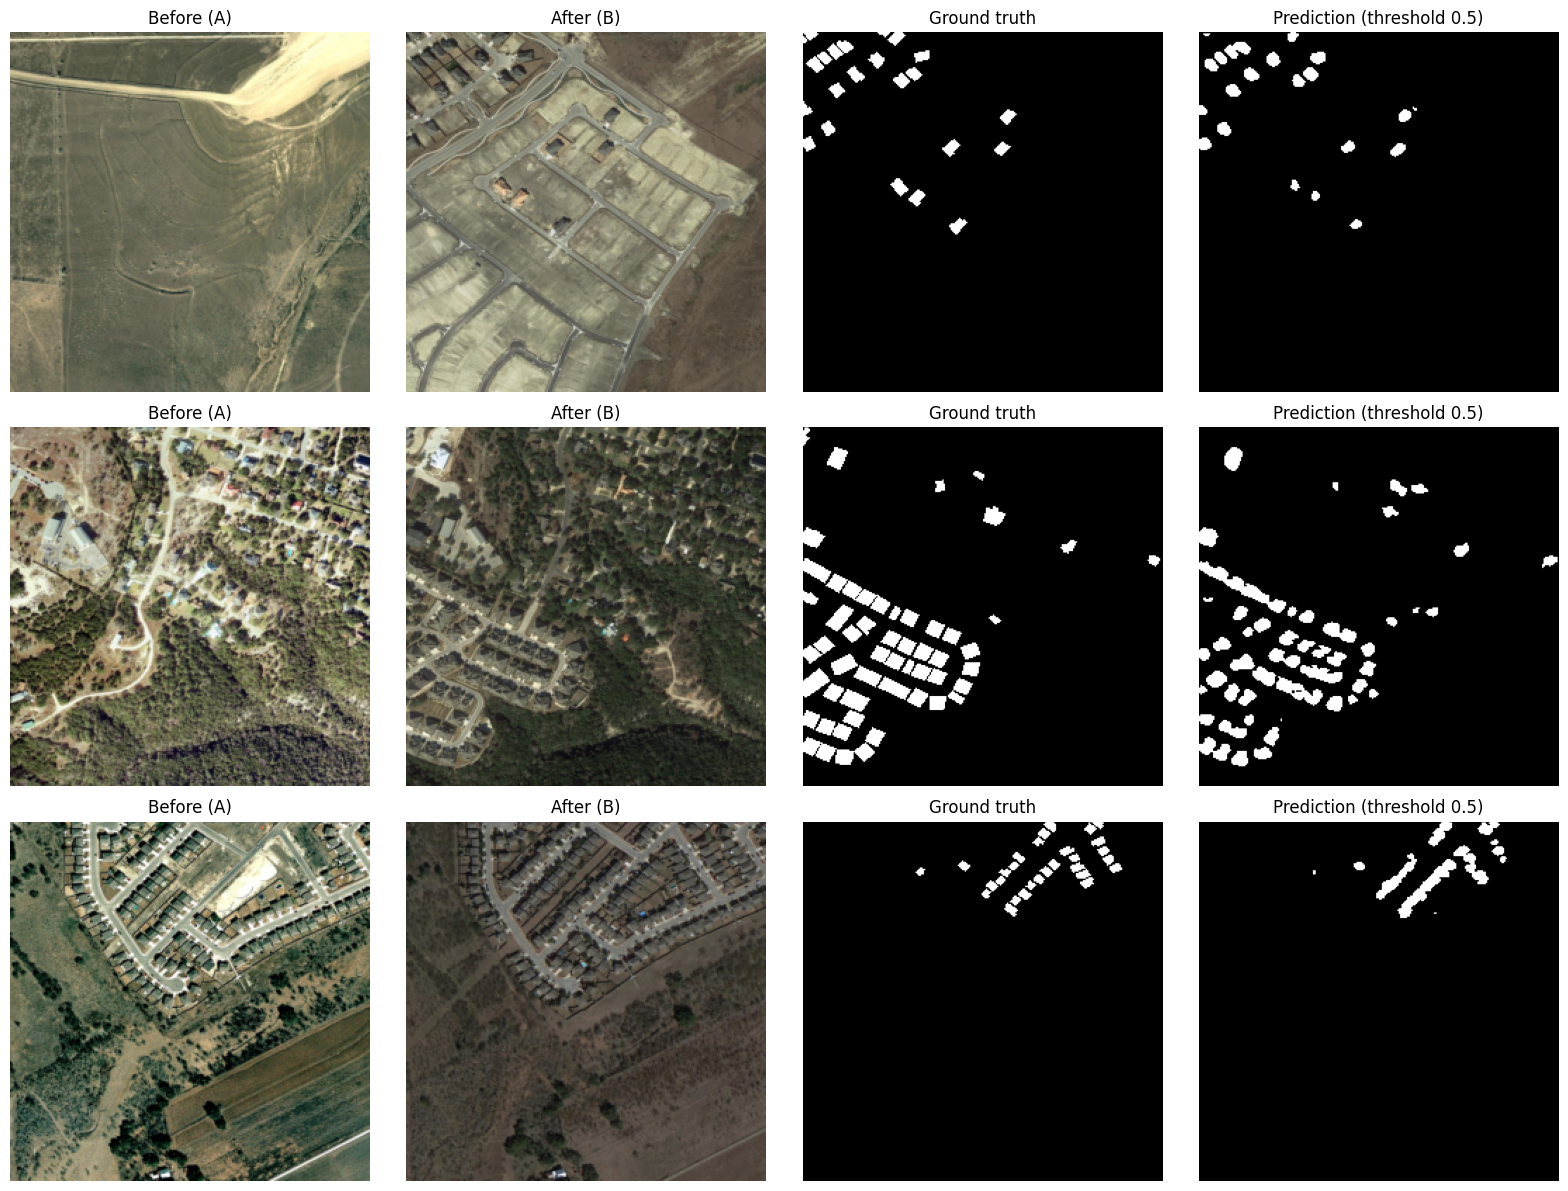

In [9]:
import matplotlib.pyplot as plt
import torch

model.eval()

# Show 3 validation examples
n_show = min(3, len(val_ds))
fig, axes = plt.subplots(n_show, 4, figsize=(16, 4 * n_show))

if n_show == 1:
    axes = axes.reshape(1, -1)

with torch.no_grad():
    for i in range(n_show):
        image, mask = val_ds[i]

        logits = model(image.unsqueeze(0).to(device))
        prob = torch.sigmoid(logits)[0, 0].cpu().numpy()
        pred = (prob >= 0.5).astype("uint8")

        # Input has 6 channels: first 3 = before, next 3 = after
        before = image[:3].permute(1, 2, 0).numpy()
        after = image[3:6].permute(1, 2, 0).numpy()
        gt = mask[0].numpy()

        axes[i, 0].imshow(before)
        axes[i, 0].set_title("Before (A)")

        axes[i, 1].imshow(after)
        axes[i, 1].set_title("After (B)")

        axes[i, 2].imshow(gt, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title("Ground truth")

        axes[i, 3].imshow(pred, cmap="gray", vmin=0, vmax=1)
        axes[i, 3].set_title("Prediction (threshold 0.5)")

        for j in range(4):
            axes[i, j].axis("off")

plt.tight_layout()
plt.show()

Validation pixels: 6225920
Positive/change pixel fraction: 0.046909854286595394

Threshold | Precision | Recall | F1 | IoU
0.10      | 0.6861    | 0.8336 | 0.7527 | 0.6034
0.15      | 0.7113    | 0.8126 | 0.7586 | 0.6111
0.20      | 0.7293    | 0.7966 | 0.7614 | 0.6148
0.25      | 0.7433    | 0.7824 | 0.7623 | 0.6160
0.30      | 0.7550    | 0.7696 | 0.7622 | 0.6158
0.35      | 0.7653    | 0.7576 | 0.7614 | 0.6148
0.40      | 0.7744    | 0.7463 | 0.7601 | 0.6130
0.45      | 0.7831    | 0.7353 | 0.7585 | 0.6109
0.50      | 0.7915    | 0.7244 | 0.7565 | 0.6084
0.55      | 0.8001    | 0.7134 | 0.7542 | 0.6055
0.60      | 0.8085    | 0.7015 | 0.7512 | 0.6015
0.65      | 0.8171    | 0.6888 | 0.7475 | 0.5968
0.70      | 0.8260    | 0.6741 | 0.7424 | 0.5903
0.75      | 0.8366    | 0.6564 | 0.7356 | 0.5818
0.80      | 0.8490    | 0.6325 | 0.7250 | 0.5686
0.85      | 0.8664    | 0.5980 | 0.7076 | 0.5475
0.90      | 0.8907    | 0.5398 | 0.6723 | 0.5063

Best validation threshold by F1: 0.25
F1=0.

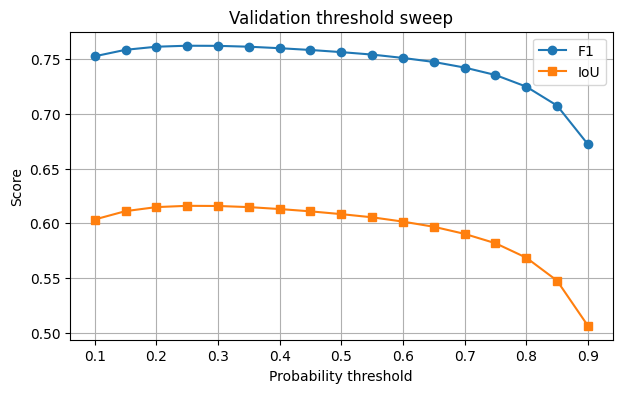


Brier score (lower is better): 0.017507
ECE (lower is better):         0.008681


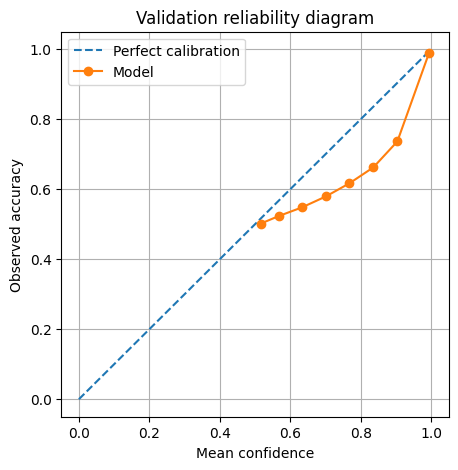


Entropy-based uncertainty check:
Error rate in most uncertain 10% pixels: 0.1876
Error rate in remaining 90% pixels:      0.0035
Uncertainty cutoff (normalized entropy):  0.0863

Coverage after withholding high-uncertainty pixels:
Coverage = fraction the model still predicts automatically
Withhold  5% | Coverage 0.950 | Error rate on retained pixels 0.0070
Withhold 10% | Coverage 0.900 | Error rate on retained pixels 0.0035
Withhold 20% | Coverage 0.800 | Error rate on retained pixels 0.0026
Withhold 30% | Coverage 0.700 | Error rate on retained pixels 0.0022


In [10]:
import numpy as np
import torch
import matplotlib.pyplot as plt

model.eval()

all_probs = []
all_targets = []

# Collect predictions ONLY from validation data
with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(device)
        logits = model(images)
        probs = torch.sigmoid(logits).cpu().numpy()

        all_probs.append(probs)
        all_targets.append(masks.numpy())

probs = np.concatenate(all_probs, axis=0).reshape(-1)
targets = np.concatenate(all_targets, axis=0).reshape(-1).astype(np.uint8)

print("Validation pixels:", len(targets))
print("Positive/change pixel fraction:", targets.mean())

# --------------------------------------------------
# 1. Threshold sweep: select threshold using validation
# --------------------------------------------------
thresholds = np.arange(0.10, 0.91, 0.05)
threshold_results = []

for threshold in thresholds:
    pred = probs >= threshold

    tp = np.sum(pred & (targets == 1))
    fp = np.sum(pred & (targets == 0))
    fn = np.sum((~pred) & (targets == 1))

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    iou = tp / (tp + fp + fn + 1e-8)

    threshold_results.append((threshold, precision, recall, f1, iou))

print("\nThreshold | Precision | Recall | F1 | IoU")
for row in threshold_results:
    print(
        f"{row[0]:.2f}      | {row[1]:.4f}    | {row[2]:.4f} | "
        f"{row[3]:.4f} | {row[4]:.4f}"
    )

best_row = max(threshold_results, key=lambda r: r[3])
best_threshold = best_row[0]

print(f"\nBest validation threshold by F1: {best_threshold:.2f}")
print(f"F1={best_row[3]:.4f}, IoU={best_row[4]:.4f}")

# Plot threshold effect
plt.figure(figsize=(7, 4))
plt.plot([r[0] for r in threshold_results],
         [r[3] for r in threshold_results], marker="o", label="F1")
plt.plot([r[0] for r in threshold_results],
         [r[4] for r in threshold_results], marker="s", label="IoU")
plt.xlabel("Probability threshold")
plt.ylabel("Score")
plt.title("Validation threshold sweep")
plt.grid(True)
plt.legend()
plt.show()

# --------------------------------------------------
# 2. Probability calibration: Brier score and ECE
# --------------------------------------------------
hard_pred = (probs >= 0.5).astype(np.uint8)
correct = (hard_pred == targets).astype(np.float32)

# Brier score: lower is better
brier = np.mean((probs - targets) ** 2)

# ECE uses confidence in the predicted class and whether that prediction is correct
confidence = np.maximum(probs, 1 - probs)
num_bins = 15
bin_edges = np.linspace(0, 1, num_bins + 1)
ece = 0.0

bin_confidences = []
bin_accuracies = []
bin_counts = []

for b in range(num_bins):
    if b == num_bins - 1:
        in_bin = (confidence >= bin_edges[b]) & (confidence <= bin_edges[b + 1])
    else:
        in_bin = (confidence >= bin_edges[b]) & (confidence < bin_edges[b + 1])

    count = in_bin.sum()
    if count == 0:
        continue

    avg_conf = confidence[in_bin].mean()
    avg_acc = correct[in_bin].mean()

    ece += (count / len(confidence)) * abs(avg_conf - avg_acc)

    bin_confidences.append(avg_conf)
    bin_accuracies.append(avg_acc)
    bin_counts.append(count)

print(f"\nBrier score (lower is better): {brier:.6f}")
print(f"ECE (lower is better):         {ece:.6f}")

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.plot(bin_confidences, bin_accuracies, marker="o", label="Model")
plt.xlabel("Mean confidence")
plt.ylabel("Observed accuracy")
plt.title("Validation reliability diagram")
plt.grid(True)
plt.legend()
plt.show()

# --------------------------------------------------
# 3. Entropy uncertainty vs prediction errors
# --------------------------------------------------
eps = 1e-7
p = np.clip(probs, eps, 1 - eps)

# Binary entropy, normalized to 0..1:
# 0 = very confident; 1 = maximally uncertain
entropy = -(p * np.log(p) + (1 - p) * np.log(1 - p)) / np.log(2)

errors = (hard_pred != targets)
high_uncertainty_fraction = 0.10
cutoff = np.quantile(entropy, 1 - high_uncertainty_fraction)

most_uncertain = entropy >= cutoff
remaining = ~most_uncertain

error_rate_uncertain = errors[most_uncertain].mean()
error_rate_remaining = errors[remaining].mean()

print("\nEntropy-based uncertainty check:")
print(f"Error rate in most uncertain 10% pixels: {error_rate_uncertain:.4f}")
print(f"Error rate in remaining 90% pixels:      {error_rate_remaining:.4f}")
print(f"Uncertainty cutoff (normalized entropy):  {cutoff:.4f}")

# --------------------------------------------------
# 4. Simple selective prediction: abstain on uncertain pixels
# --------------------------------------------------
print("\nCoverage after withholding high-uncertainty pixels:")
print("Coverage = fraction the model still predicts automatically")

for withheld_fraction in [0.05, 0.10, 0.20, 0.30]:
    cutoff = np.quantile(entropy, 1 - withheld_fraction)
    retained = entropy < cutoff

    coverage = retained.mean()
    retained_error = errors[retained].mean() if retained.any() else np.nan

    print(
        f"Withhold {withheld_fraction:>3.0%} | "
        f"Coverage {coverage:.3f} | "
        f"Error rate on retained pixels {retained_error:.4f}"
    )

Validation images: 95
Image prediction shape: (95, 256, 256)
Operating threshold: 0.25

Selective review results:


,operating_threshold,withheld_uncertain_fraction,uncertainty_cutoff,automatic_prediction_coverage,error_rate_on_retained_pixels,error_rate_in_withheld_pixels
0,0.25,0.05,0.212687,0.950000,0.006956,0.325522
1,0.25,0.10,0.086304,0.899999,0.003466,0.197653
2,0.25,0.20,0.064986,0.800000,0.002582,0.104096
3,0.25,0.30,0.055876,0.700000,0.002231,0.071075



Per-image metric summary:


,validation_image_index,operating_threshold,precision,recall,f1,iou,ground_truth_change_fraction,predicted_change_fraction,pixel_error_rate,top_10_percent_uncertainty_error_rate,mean_entropy
count,95.0000,95.00,95.0000,95.0000,95.0000,95.0000,95.0000,95.0000,95.0000,95.0000,95.0000
mean,47.0000,0.25,0.6076,0.6772,0.6169,0.4947,0.0469,0.0494,0.0229,0.1694,0.0699
std,27.5681,0.00,0.2774,0.2994,0.2805,0.2449,0.0493,0.0504,0.0203,0.1270,0.0334
min,0.0000,0.25,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0275
25%,23.5000,0.25,0.5227,0.6598,0.5586,0.3875,0.0085,0.0097,0.0072,0.0605,0.0441
50%,47.0000,0.25,0.7192,0.7859,0.7515,0.6020,0.0293,0.0330,0.0163,0.1436,0.0601
75%,70.5000,0.25,0.7893,0.8779,0.8043,0.6726,0.0707,0.0769,0.0351,0.2746,0.0868
max,94.0000,0.25,0.9889,1.0000,0.8682,0.7672,0.1992,0.2119,0.0788,0.4771,0.1685



Calibration summary:
{
  "operating_threshold": 0.25,
  "brier_score": 0.01750686578452587,
  "ece": 0.008708729557441218,
  "number_of_calibration_bins": 15,
  "note": "Pixel-level pooled calibration. Because unchanged pixels dominate, also inspect class-specific or image-level calibration before drawing strong conclusions."
}


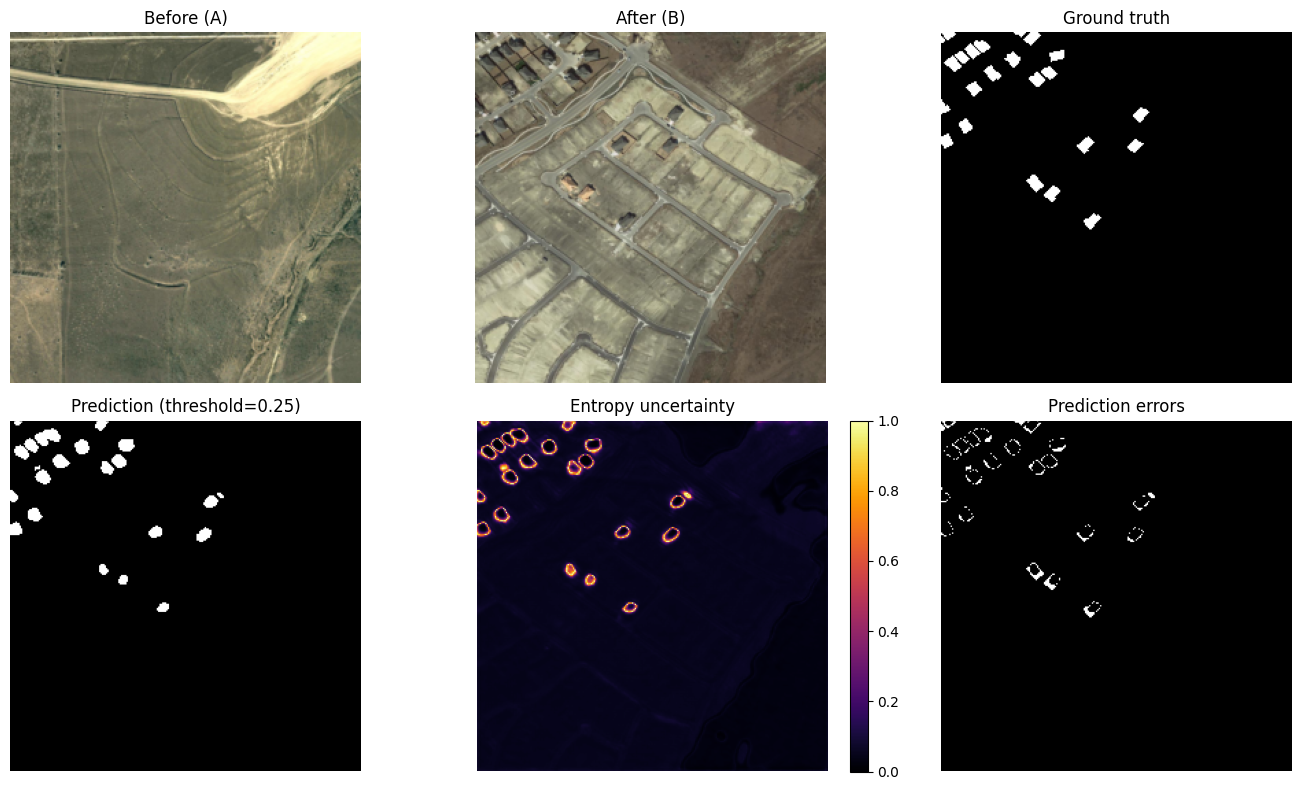


Saved experiment files:
  calibration_bins.csv (1.2 KB)
  calibration_summary.json (0.3 KB)
  experiment_summary.json (0.7 KB)
  per_image_validation_metrics.csv (15.8 KB)
  selective_review_results.csv (0.5 KB)
  uncertainty_error_enrichment.json (0.2 KB)
  validation_pixel_arrays.npz (43071.6 KB)
  validation_uncertainty_example.png (1535.0 KB)

ZIP archive created:
/kaggle/working/LEVIR_uncertainty_validation_results.zip


In [11]:
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# ============================================================
# 0. Output folder and experiment settings
# ============================================================
RESULTS_DIR = Path("/kaggle/working/uncertainty_validation_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

OPERATING_THRESHOLD = 0.25  # chosen from LEVIR-CD validation threshold sweep
UNCERTAINTY_FRACTIONS = [0.05, 0.10, 0.20, 0.30]

model.eval()

# ============================================================
# 1. Collect predictions and labels for validation images
# ============================================================
image_probs = []
image_targets = []

with torch.no_grad():
    for images, masks in val_loader:
        logits = model(images.to(device))
        batch_probs = torch.sigmoid(logits).cpu().numpy()[:, 0]  # B,H,W
        batch_targets = masks.cpu().numpy()[:, 0]                # B,H,W

        image_probs.extend(batch_probs)
        image_targets.extend(batch_targets)

image_probs = np.asarray(image_probs, dtype=np.float32)
image_targets = (np.asarray(image_targets) >= 0.5).astype(np.uint8)

preds = (image_probs >= OPERATING_THRESHOLD).astype(np.uint8)
errors = (preds != image_targets)

# Binary entropy: normalized to [0,1]
eps = 1e-7
p = np.clip(image_probs, eps, 1 - eps)
entropy = (
    -(p * np.log(p) + (1 - p) * np.log(1 - p)) / np.log(2)
).astype(np.float32)

print("Validation images:", len(image_probs))
print("Image prediction shape:", image_probs.shape)
print("Operating threshold:", OPERATING_THRESHOLD)

# ============================================================
# 2. Save pooled selective-review results
# ============================================================
flat_errors = errors.reshape(-1)
flat_entropy = entropy.reshape(-1)

selective_rows = []

for withheld_fraction in UNCERTAINTY_FRACTIONS:
    cutoff = np.quantile(flat_entropy, 1 - withheld_fraction)
    retained = flat_entropy < cutoff

    coverage = float(retained.mean())
    retained_error_rate = (
        float(flat_errors[retained].mean()) if retained.any() else np.nan
    )

    uncertain = ~retained
    uncertain_error_rate = (
        float(flat_errors[uncertain].mean()) if uncertain.any() else np.nan
    )

    selective_rows.append({
        "operating_threshold": OPERATING_THRESHOLD,
        "withheld_uncertain_fraction": withheld_fraction,
        "uncertainty_cutoff": float(cutoff),
        "automatic_prediction_coverage": coverage,
        "error_rate_on_retained_pixels": retained_error_rate,
        "error_rate_in_withheld_pixels": uncertain_error_rate,
    })

selective_df = pd.DataFrame(selective_rows)
selective_csv = RESULTS_DIR / "selective_review_results.csv"
selective_df.to_csv(selective_csv, index=False)

print("\nSelective review results:")
display(selective_df)

# Error enrichment: top 10% uncertainty versus remaining 90%
cutoff_10 = np.quantile(flat_entropy, 0.90)
top_uncertain = flat_entropy >= cutoff_10
other_pixels = ~top_uncertain

top10_error = float(flat_errors[top_uncertain].mean())
other90_error = float(flat_errors[other_pixels].mean())

error_enrichment = {
    "operating_threshold": OPERATING_THRESHOLD,
    "top_uncertainty_fraction": 0.10,
    "top_10_percent_error_rate": top10_error,
    "remaining_90_percent_error_rate": other90_error,
    "error_rate_ratio_top10_vs_remaining": (
        top10_error / other90_error if other90_error > 0 else None
    ),
}

with open(RESULTS_DIR / "uncertainty_error_enrichment.json", "w") as f:
    json.dump(error_enrichment, f, indent=2)

# ============================================================
# 3. Calculate per-image metrics
# ============================================================
per_image_rows = []

for i in range(len(image_probs)):
    gt = image_targets[i].astype(bool)
    pred = preds[i].astype(bool)
    err = errors[i]
    unc = entropy[i]

    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, ~gt).sum()
    fn = np.logical_and(~pred, gt).sum()

    precision = tp / (tp + fp + 1e-8)
    recall = tp / (tp + fn + 1e-8)
    f1 = 2 * precision * recall / (precision + recall + 1e-8)
    iou = tp / (tp + fp + fn + 1e-8)

    # Error rate among the most uncertain 10% pixels within this image
    image_cutoff = np.quantile(unc, 0.90)
    image_top_uncertain = unc >= image_cutoff

    per_image_rows.append({
        "validation_image_index": i,
        "operating_threshold": OPERATING_THRESHOLD,
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "iou": float(iou),
        "ground_truth_change_fraction": float(gt.mean()),
        "predicted_change_fraction": float(pred.mean()),
        "pixel_error_rate": float(err.mean()),
        "top_10_percent_uncertainty_error_rate": float(
            err[image_top_uncertain].mean()
        ),
        "mean_entropy": float(unc.mean()),
    })

per_image_df = pd.DataFrame(per_image_rows)
per_image_csv = RESULTS_DIR / "per_image_validation_metrics.csv"
per_image_df.to_csv(per_image_csv, index=False)

print("\nPer-image metric summary:")
display(per_image_df.describe().round(4))

# ============================================================
# 4. Calibration measures at the selected operating threshold
# ============================================================
flat_probs = image_probs.reshape(-1)
flat_targets = image_targets.reshape(-1)

# Brier score measures probability quality
brier_score = float(np.mean((flat_probs - flat_targets) ** 2))

# ECE based on confidence in the predicted class at threshold 0.25
flat_preds = (flat_probs >= OPERATING_THRESHOLD).astype(np.uint8)
flat_confidence = np.where(flat_preds == 1, flat_probs, 1 - flat_probs)
flat_correct = (flat_preds == flat_targets).astype(np.float32)

num_bins = 15
bin_edges = np.linspace(0, 1, num_bins + 1)
ece = 0.0
calibration_rows = []

for b in range(num_bins):
    if b == num_bins - 1:
        in_bin = (
            (flat_confidence >= bin_edges[b])
            & (flat_confidence <= bin_edges[b + 1])
        )
    else:
        in_bin = (
            (flat_confidence >= bin_edges[b])
            & (flat_confidence < bin_edges[b + 1])
        )

    count = int(in_bin.sum())
    if count == 0:
        continue

    mean_confidence = float(flat_confidence[in_bin].mean())
    observed_accuracy = float(flat_correct[in_bin].mean())
    bin_weight = count / len(flat_confidence)

    ece += bin_weight * abs(mean_confidence - observed_accuracy)

    calibration_rows.append({
        "bin_lower": float(bin_edges[b]),
        "bin_upper": float(bin_edges[b + 1]),
        "pixel_count": count,
        "mean_confidence": mean_confidence,
        "observed_accuracy": observed_accuracy,
        "absolute_calibration_gap": abs(mean_confidence - observed_accuracy),
    })

calibration_df = pd.DataFrame(calibration_rows)
calibration_df.to_csv(RESULTS_DIR / "calibration_bins.csv", index=False)

calibration_summary = {
    "operating_threshold": OPERATING_THRESHOLD,
    "brier_score": brier_score,
    "ece": float(ece),
    "number_of_calibration_bins": num_bins,
    "note": (
        "Pixel-level pooled calibration. Because unchanged pixels dominate, "
        "also inspect class-specific or image-level calibration before drawing "
        "strong conclusions."
    ),
}

with open(RESULTS_DIR / "calibration_summary.json", "w") as f:
    json.dump(calibration_summary, f, indent=2)

print("\nCalibration summary:")
print(json.dumps(calibration_summary, indent=2))

# ============================================================
# 5. Save a visualization of one validation example
# ============================================================
example_idx = 0

# val_loader is not shuffled, so this corresponds to val_ds[example_idx]
example_image, _ = val_ds[example_idx]

before = example_image[:3].permute(1, 2, 0).numpy()
after = example_image[3:6].permute(1, 2, 0).numpy()

gt = image_targets[example_idx]
pred = preds[example_idx]
unc = entropy[example_idx]
err = errors[example_idx]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0, 0].imshow(before)
axes[0, 0].set_title("Before (A)")

axes[0, 1].imshow(after)
axes[0, 1].set_title("After (B)")

axes[0, 2].imshow(gt, cmap="gray", vmin=0, vmax=1)
axes[0, 2].set_title("Ground truth")

axes[1, 0].imshow(pred, cmap="gray", vmin=0, vmax=1)
axes[1, 0].set_title(f"Prediction (threshold={OPERATING_THRESHOLD})")

im = axes[1, 1].imshow(unc, cmap="inferno", vmin=0, vmax=1)
axes[1, 1].set_title("Entropy uncertainty")
fig.colorbar(im, ax=axes[1, 1], fraction=0.046)

axes[1, 2].imshow(err, cmap="gray", vmin=0, vmax=1)
axes[1, 2].set_title("Prediction errors")

for ax in axes.ravel():
    ax.axis("off")

fig.tight_layout()

visualization_path = RESULTS_DIR / "validation_uncertainty_example.png"
fig.savefig(visualization_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# ============================================================
# 6. Save compressed pixel-level arrays for future analysis
# ============================================================
# This preserves the pixel values without creating a huge plain CSV.
pixel_arrays_path = RESULTS_DIR / "validation_pixel_arrays.npz"

np.savez_compressed(
    pixel_arrays_path,
    probabilities=image_probs,
    targets=image_targets,
    predictions=preds,
    entropy=entropy,
    errors=errors.astype(np.uint8),
)

# ============================================================
# 7. Save a single experiment summary JSON
# ============================================================
experiment_summary = {
    "experiment": "LEVIR-CD validation uncertainty/selective review",
    "operating_threshold": OPERATING_THRESHOLD,
    "validation_images": int(len(image_probs)),
    "validation_image_size": list(image_probs.shape[1:]),
    "validation_positive_pixel_fraction": float(image_targets.mean()),
    "pooled_pixel_error_rate": float(errors.mean()),
    "top_10_percent_uncertainty_error_rate": top10_error,
    "remaining_90_percent_error_rate": other90_error,
    "brier_score": brier_score,
    "ece": float(ece),
    "outputs": [
        "selective_review_results.csv",
        "per_image_validation_metrics.csv",
        "calibration_bins.csv",
        "calibration_summary.json",
        "uncertainty_error_enrichment.json",
        "validation_uncertainty_example.png",
        "validation_pixel_arrays.npz",
    ],
}

summary_path = RESULTS_DIR / "experiment_summary.json"
with open(summary_path, "w") as f:
    json.dump(experiment_summary, f, indent=2)

# ============================================================
# 8. Bundle all outputs into one downloadable ZIP
# ============================================================
zip_base = Path("/kaggle/working/LEVIR_uncertainty_validation_results")
zip_path = shutil.make_archive(
    str(zip_base),
    "zip",
    root_dir=RESULTS_DIR
)

print("\nSaved experiment files:")
for path in sorted(RESULTS_DIR.iterdir()):
    print(f"  {path.name} ({path.stat().st_size / 1024:.1f} KB)")

print("\nZIP archive created:")
print(zip_path)

In [12]:
import numpy as np
import pandas as pd
import json
import shutil
from pathlib import Path

RESULTS_DIR = Path("/kaggle/working/uncertainty_validation_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

review_fractions = [0.05, 0.10, 0.20, 0.30]
rows = []

for i in range(len(image_probs)):
    img_entropy = entropy[i].reshape(-1)
    img_errors = errors[i].reshape(-1)

    total_error = float(img_errors.mean())

    for review_fraction in review_fractions:
        cutoff = np.quantile(img_entropy, 1 - review_fraction)

        # Withhold the highest-entropy pixels
        withheld = img_entropy >= cutoff
        retained = ~withheld

        retained_error = (
            float(img_errors[retained].mean()) if retained.any() else np.nan
        )
        withheld_error = (
            float(img_errors[withheld].mean()) if withheld.any() else np.nan
        )

        rows.append({
            "validation_image_index": i,
            "review_fraction": review_fraction,
            "automatic_coverage": float(retained.mean()),
            "overall_pixel_error_rate": total_error,
            "retained_pixel_error_rate": retained_error,
            "withheld_pixel_error_rate": withheld_error,
            "error_rate_reduction_vs_all_pixels": (
                1 - retained_error / total_error if total_error > 0 else np.nan
            ),
        })

per_image_selective_df = pd.DataFrame(rows)

csv_path = RESULTS_DIR / "per_image_selective_review.csv"
per_image_selective_df.to_csv(csv_path, index=False)

# Summarize across scenes
summary_df = (
    per_image_selective_df
    .groupby("review_fraction")
    .agg(
        mean_coverage=("automatic_coverage", "mean"),
        mean_all_pixel_error=("overall_pixel_error_rate", "mean"),
        mean_retained_error=("retained_pixel_error_rate", "mean"),
        median_retained_error=("retained_pixel_error_rate", "median"),
        mean_withheld_error=("withheld_pixel_error_rate", "mean"),
        mean_error_reduction=("error_rate_reduction_vs_all_pixels", "mean"),
        fraction_images_improved=(
            "error_rate_reduction_vs_all_pixels",
            lambda x: float((x > 0).mean())
        ),
    )
    .reset_index()
)

summary_csv = RESULTS_DIR / "per_image_selective_review_summary.csv"
summary_df.to_csv(summary_csv, index=False)

print("Per-image selective-review summary:")
display(summary_df.round(4))

# Save a machine-readable summary
summary_json_path = RESULTS_DIR / "per_image_selective_review_summary.json"
summary_df.to_json(summary_json_path, orient="records", indent=2)

# Create updated ZIP containing the original files plus this analysis
zip_base = Path("/kaggle/working/LEVIR_uncertainty_validation_results_updated")
zip_path = shutil.make_archive(
    str(zip_base),
    "zip",
    root_dir=RESULTS_DIR
)

print("\nUpdated ZIP:", zip_path)

Per-image selective-review summary:


,review_fraction,mean_coverage,mean_all_pixel_error,mean_retained_error,median_retained_error,mean_withheld_error,mean_error_reduction,fraction_images_improved
0,0.05,0.95,0.0229,0.0107,0.0030,0.2545,0.6999,0.9789
1,0.10,0.90,0.0229,0.0066,0.0016,0.1694,0.8084,0.9789
2,0.20,0.80,0.0229,0.0034,0.0011,0.1007,0.8805,0.9789
3,0.30,0.70,0.0229,0.0024,0.0008,0.0707,0.9063,0.9789



Updated ZIP: /kaggle/working/LEVIR_uncertainty_validation_results_updated.zip


In [13]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    # Show folders and a few files, to a limited depth
    relative = root.replace("/kaggle/input", "")
    depth = relative.count(os.sep)

    if depth <= 4:
        print("  " * depth + os.path.basename(root) + "/")
        for f in files[:5]:
            print("  " * (depth + 1) + f)

input/
  datasets/
    simranmaniyar/
      levir-cd-change-detection/
        LEVIR-CD+/
          README.md
      s-looking/
        S2Looking/
